# Qwen3: native TPR steering results

Compare raw centroids, TPR role swaps, and Soft TPR slot swaps on the completed layers 20–22 experiment. We look at the baseline preference, answer logits, prediction flips, and edit sizes, then inspect the local representation diagnostics.

Each condition edits both nouns together at one layer, at α = 1 with unmatched norms. The prompt asks **Who or what is performing the action?** Scores compare the two noun answers at the final answer position; ties favor neither. The model is **Qwen3-8B-Base**.

This notebook reads saved results and checks them on CPU. The [TPR](native_tpr_role_swap.ipynb) and [Soft TPR](native_soft_tpr_slot_swap.ipynb) walkthroughs explain the edits. The [all-layer comparison](role_interventions_comparison_qwen3.ipynb) also includes reconstructed centroids.


## Load the run

Run from the repository root or `notebook/` with the experiment environment, Jupyter, pandas, and matplotlib. Set `AC_TPR_NATIVE_RUN` to use another compatible completed run. The reference artifacts and checkpoints must be available: the audit helpers check their hashes and every saved evaluation condition.


In [1]:
%matplotlib inline
import hashlib
from pathlib import Path
from types import SimpleNamespace
import os
import sys
import json
import platform


In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
assert (ROOT / "scripts/temporary/run_native_tpr_nov6.py").is_file(), "Run from the repository root or notebook directory"
RUN = Path(os.environ.get("AC_TPR_NATIVE_RUN", str(ROOT / "ac-tpr-cache/native-tpr-nov6-20261108"))).expanduser().resolve()
for directory in (Path("/tmp/ac-tpr-nov6-extra"), ROOT / "src", ROOT / "scripts/temporary"):
    if directory.is_dir() and str(directory) not in sys.path:
        sys.path.insert(0, str(directory))


In [3]:
import torch
import numpy as np
import pandas as pd
from IPython.display import display
from run_tpr_nov6 import digest
from run_native_tpr_nov6 import load_plan, verify_calibration, read_csv, METHODS, summarize
from report_native_tpr_nov6 import audit_stage, audit_stage_metadata, audit_runtime, audit_calibration
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter


/tmp/tpr-binding-gpu-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Check the plan and source files


In [4]:
%matplotlib inline
torch.set_num_threads(2)
declared_plan = json.loads((RUN / "plan.json").read_text())
args = SimpleNamespace(run_dir=RUN, batch_size=declared_plan["batch_size"])
plan, reference = load_plan(args)
verify_calibration(args)
assert digest(ROOT / "data/active_pass_long/corpus.csv") == plan["corpus_sha256"]
input_hashes = {
    str(RUN / "plan.json"): digest(RUN / "plan.json"),
    str(ROOT / "data/active_pass_long/corpus.csv"): plan["corpus_sha256"],
}
for name, expected in plan["source_sha256"].items():
    input_hashes[str(ROOT / name)] = expected


In [5]:
METHOD_LABELS = {
    "raw_centroid": "Raw centroid",
    "tpr_native_role_swap": "Native TPR role swap",
    "soft_native_slot_swap": "Native Soft TPR slot swap",
}
SPLIT_LABELS = {"val": "Validation", "test": "Test", "gen_test": "Generalization test"}
SPLITS = ["test", "gen_test"]
VOICES = ["active", "passive"]
GROUPS = ["split", "voice"]
KEYS = GROUPS + ["layer", "method"]
FIGURES_ROOT = ROOT / "notebook/figures/native_tpr_steering_results"
LAYERS = plan["layers"]


### Run settings


In [6]:
display(pd.DataFrame([
    {"Field": "Run", "Value": str(RUN)},
    {"Field": "Model", "Value": plan["model"]},
    {"Field": "Model revision", "Value": plan["revision"]},
    {"Field": "Frozen Python / current", "Value": f'{plan["runtime"]["python"]} / {platform.python_version()}'},
    {"Field": "Frozen PyTorch / current", "Value": f'{plan["runtime"]["torch"]} / {torch.__version__}'},
    {"Field": "Layers (zero-based)", "Value": str(LAYERS)},
    {"Field": "Strength", "Value": str(plan["fixed_alpha"])},
    {"Field": "Norm matching", "Value": str(plan["norm_matching"])},
]))


,Field,Value
0,Run,/home/ldomenichelli/Workspace/AC-TPR-native-no...
1,Model,Qwen/Qwen3-8B-Base
2,Model revision,49e3418fbbbca6ecbdf9608b4d22e5a407081db4
3,Frozen Python / current,3.12.3 / 3.12.3
4,Frozen PyTorch / current,2.13.0+cu130 / 2.13.0+cu130
5,Layers (zero-based),"[20, 21, 22]"
6,Strength,1.0
7,Norm matching,False


### Check the saved evaluation

Verify the validation and held-out conditions, their summaries, and the recorded runtime.


In [7]:
audit_inputs = {}
stage_summaries = {}
stage_frames = {}
coverage = []
norm_reference = Path(plan["norm_reference_run"])
for stage in ("validation", "evaluation"):
    folder = RUN / stage
    metadata = json.loads((folder / "metadata.json").read_text())
    assert metadata["status"] == "complete"
    assert digest(folder / "results.csv") == metadata["results_sha256"]
    baseline_rows = read_csv(folder / "baseline.csv")
    result_rows = read_csv(folder / "results.csv")
    supplied_summary = read_csv(folder / "summary.csv")
    checked = audit_stage(
        baseline_rows, result_rows, supplied_summary,
        read_csv(norm_reference / stage / "baseline.csv"),
        read_csv(norm_reference / stage / "results.csv"), stage,
    )
    audit_stage_metadata(metadata, result_rows, RUN)
    audit_runtime(RUN, stage, plan, audit_inputs)
    stage_summaries[stage] = pd.DataFrame(checked)
    stage_frames[stage] = pd.DataFrame(result_rows)
    coverage.append({"Stage": stage, "Sentences": len(baseline_rows),
                     "Result rows": len(result_rows), "Groups": len(checked)})
    for name in ("metadata.json", "baseline.csv", "results.csv", "summary.csv"):
        path = folder / name
        input_hashes[str(path)] = digest(path)

input_hashes.update({str(path): digest(path) for path in audit_inputs.values()})


In [8]:
full_summary = stage_summaries["evaluation"]
assert len(full_summary) == len(LAYERS) * len(METHODS) * 2 * len(VOICES)
display(pd.DataFrame(coverage))


,Stage,Sentences,Result rows,Groups
0,validation,412,3708,18
1,evaluation,2096,18864,36


### Load answers and sentence annotations


In [9]:
baseline_all = pd.read_csv(RUN / "evaluation/baseline.csv")
results_all = pd.read_csv(RUN / "evaluation/results.csv")
corpus = pd.read_csv(ROOT / "data/active_pass_long/corpus.csv").rename_axis("row_id").reset_index()
assert not baseline_all.row_id.duplicated().any()
assert not results_all.duplicated(["row_id", "layer", "method"]).any()
assert set(results_all.row_id) == set(baseline_all.row_id)
# row_id is the row position in the hash-verified extraction corpus.
annotations = corpus.set_index("row_id").loc[baseline_all.row_id]
for column in ["split", "voice", "agent", "patient"]:
    np.testing.assert_array_equal(baseline_all[column], annotations[column])
quad_ids = results_all.row_id.map(corpus.set_index("row_id").quad_id)
np.testing.assert_array_equal(results_all.quad_id, quad_ids)


In [10]:
FILTER_COLUMNS = [
    "subset", "verb_class", "np_type", "animacy_config", "animacy_hierarchy",
    "agent_animacy", "patient_animacy", "swapped",
]
baseline_all = baseline_all.merge(corpus[["row_id"] + FILTER_COLUMNS], on="row_id", validate="one_to_one")
display(pd.DataFrame([
    {"column": column, "value": value, "sentences": count}
    for column in FILTER_COLUMNS
    for value, count in baseline_all[column].value_counts().sort_index().items()
]))


,column,value,sentences
0,subset,mixed_contact,656
1,subset,names_agentive,628
2,subset,nouns_contact,812
3,verb_class,agentive,628
4,verb_class,contact,1468
5,np_type,mixed,656
6,np_type,name,628
7,np_type,noun,812
8,animacy_config,AA,1148
9,animacy_config,AI,374


## Choose the sentences

Set a filter to a list, or leave it as `None` for all values. Different columns combine with AND. Available values and counts are shown above; `AA`, `AI`, `IA`, and `II` give agent then patient animacy. Rerun from the next cell after changing a filter.

The language-model tables, plots, and edit norms follow the selection, with a separate export directory for each selection. The later calibration and local diagnostics use their full saved cohorts: those aggregate files cannot be filtered by sentence annotation. Training and calibration stay fixed.


In [11]:
# None includes every value; a list selects one or more values.
FILTERS = {
    "subset": None,             # ["names_agentive"], ["nouns_contact"], ["mixed_contact"]
    "verb_class": None,         # ["agentive"], ["contact"]
    "np_type": None,            # ["name"], ["noun"], ["mixed"]
    "animacy_config": None,     # ["AA"], ["AI"], ["IA"], ["II"] (agent, patient)
    "animacy_hierarchy": None,  # ["equal"], ["aligned"], ["inverted"]
    "agent_animacy": None,      # ["animate"], ["inanimate"]
    "patient_animacy": None,    # ["animate"], ["inanimate"]
    "swapped": None,            # [0], [1]
}


In [12]:
baseline = baseline_all.copy()
active_filters = {}
for column, values in FILTERS.items():
    assert column in FILTER_COLUMNS, f"Unknown filter column: {column}"
    if values is None:
        continue
    assert isinstance(values, list) and values, f"Use a nonempty list or None for {column}"
    assert set(values) <= set(baseline_all[column].unique()), f"Unknown values for {column}: {values}"
    baseline = baseline.loc[baseline[column].isin(values)].copy()
    active_filters[column] = values
assert not baseline.empty, "No sentences match FILTERS; change the selection"
results = results_all.merge(baseline[["row_id"]], on="row_id", how="inner", validate="many_to_one")
assert len(results) == len(baseline) * len(LAYERS) * len(METHODS)
FILTER_LABEL = "; ".join(f"{column}={','.join(map(str, values))}" for column, values in active_filters.items()) or "All sentences"
selection = json.dumps(active_filters, sort_keys=True)
folder = "all" if not active_filters else "filtered-" + hashlib.sha256(selection.encode()).hexdigest()[:12]
FIGURES = FIGURES_ROOT / folder


### Compute scores and strict flips

Reverse the saved patient − agent margins for the plots below.


In [13]:
# Saved margins use patient minus agent; reverse the sign for these plots.
baseline["agent_minus_patient"] = baseline.agent_logit - baseline.patient_logit
results["baseline_agent_minus_patient"] = -results.baseline_margin
results["agent_minus_patient"] = -results.edited_margin
np.testing.assert_array_equal(
    results.baseline_agent_minus_patient,
    results.row_id.map(baseline.set_index("row_id").agent_minus_patient),
)
before, after = results.baseline_agent_minus_patient, results.agent_minus_patient
results["prediction_flipped"] = ((before > 0) & (after < 0)) | ((before < 0) & (after > 0))
layer_stats = results.groupby(KEYS).agg(
    sentences=("agent_minus_patient", "size"),
    mean_agent_minus_patient=("agent_minus_patient", "mean"),
    prediction_flips=("prediction_flipped", "sum"),
    flip_rate=("prediction_flipped", "mean"),
).reset_index()


Keep the conditional flip rates and norm statistics from the original summary as well.


In [14]:
# Keep the original conditional-flip and edit-norm calculations too.
summary = pd.DataFrame(summarize(results.to_dict("records")))
summary = summary.merge(layer_stats, on=KEYS + ["sentences"], validate="one_to_one")
expected_keys = pd.MultiIndex.from_tuples([
    (*group, layer, method)
    for group in baseline.groupby(GROUPS).groups
    for layer in LAYERS for method in METHODS
], names=KEYS)
assert summary.set_index(KEYS).index.sort_values().equals(expected_keys.sort_values())
assert summary.flip_rate.between(0, 1).all()
assert (summary.prediction_flips >= summary.flips).all()
print("Selection:", FILTER_LABEL)
print(f"{len(baseline):,} / {len(baseline_all):,} sentences; {len(results):,} interventions; layers {LAYERS}")


Selection: All sentences
2,096 / 2,096 sentences; 18,864 interventions; layers [20, 21, 22]


## Before steering

Count sentences with `baseline_agent_logit > baseline_patient_logit` over all sentences in each panel. Ties are not agent wins.


In [15]:
baseline_stats = baseline.groupby(GROUPS).agg(
    sentences=("agent_minus_patient", "size"),
    agent_wins=("agent_minus_patient", lambda values: (values > 0).sum()),
    mean_agent_minus_patient=("agent_minus_patient", "mean"),
).reindex(pd.MultiIndex.from_product([SPLITS, VOICES], names=GROUPS))
baseline_stats[["sentences", "agent_wins"]] = baseline_stats[["sentences", "agent_wins"]].fillna(0).astype(int)
baseline_stats["agent_preference"] = baseline_stats.agent_wins / baseline_stats.sentences
for group, rows in summary.groupby(GROUPS):
    assert (rows.sentences == baseline_stats.loc[group, "sentences"]).all()
display(baseline_stats[["sentences", "agent_wins", "agent_preference"]].round(4))
print(f"Overall agent preference: {baseline_stats.agent_wins.sum():,} / "
      f"{baseline_stats.sentences.sum():,} "
      f"({baseline_stats.agent_wins.sum() / baseline_stats.sentences.sum():.1%})")


sentences  agent_wins  agent_preference
split    voice                                           
test     active         208         208            1.0000
         passive        208         208            1.0000
gen_test active         840         840            1.0000
         passive        840         839            0.9988

Overall agent preference: 2,095 / 2,096 (100.0%)


In [16]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#94a3b8",
    "axes.labelcolor": "#334155",
    "xtick.color": "#475569",
    "ytick.color": "#475569",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "figure.dpi": 130,
})
COLORS = {"raw_centroid": "#64748b", "tpr_native_role_swap": "#0072B2", "soft_native_slot_swap": "#D55E00"}
FIGURES.mkdir(parents=True, exist_ok=True)

def show_figure(fig):
    """Display the figure inline and release its plotting resources."""
    plt.show()
    plt.close(fig)


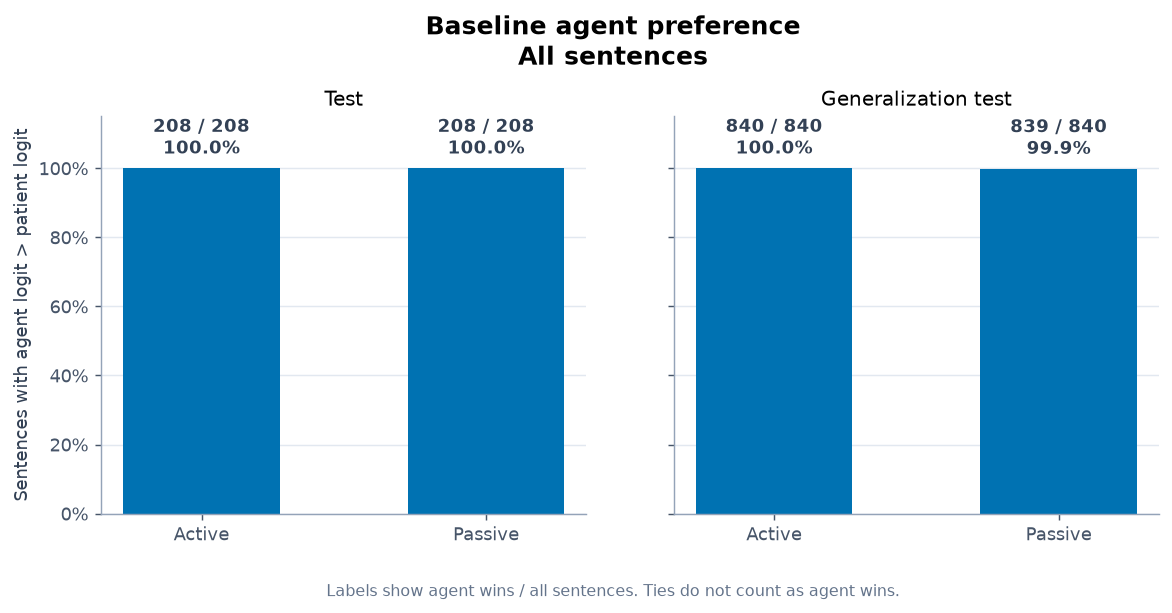

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.7), sharey=True)
for ax, split in zip(axes, SPLITS):
    stats = baseline_stats.loc[split].reindex(VOICES)
    ax.bar(np.arange(2), stats.agent_preference, width=0.55, color="#0072B2")
    for x, row in enumerate(stats.itertuples()):
        if row.sentences == 0:
            ax.text(x, 0.03, "No matching sentences", ha="center", va="bottom", fontsize=9)
            continue
        ax.text(x, row.agent_preference + 0.025,
                f"{row.agent_wins:,} / {row.sentences:,}\n{row.agent_preference:.1%}",
                ha="center", va="bottom", color="#334155", weight="bold")
    ax.set_title("Test" if split == "test" else "Generalization test")
    ax.set_xticks(range(2), [voice.capitalize() for voice in VOICES])
    ax.set_ylim(0, 1.15)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#e2e8f0")
axes[0].set_ylabel("Sentences with agent logit > patient logit")
fig.suptitle(f"Baseline agent preference\n{FILTER_LABEL}", fontsize=14, weight="bold", y=0.99)
fig.text(0.5, 0.035, "Labels show agent wins / all sentences. Ties do not count as agent wins.",
         ha="center", color="#64748b", fontsize=9)
fig.subplots_adjust(top=0.82, bottom=0.17, wspace=0.18)
show_figure(fig)


## Answer logits across layers

Positive agent − patient logits favor the agent. Each curve averages all selected sentences; the dotted line is the unedited baseline. Only the three recorded layers are shown.


Use one plotting helper to keep the panels and axes consistent.


In [18]:
def plot_layers(metric, title, ylabel, footnote, *, reference=False, percent=False, conditional=False):
    """Compare native methods using common axes across split/voice panels."""
    fig, axes = plt.subplots(2, 2, figsize=(11.5, 8), sharex=True, sharey=True)
    for row_index, split in enumerate(SPLITS):
        for col_index, voice in enumerate(VOICES):
            ax = axes[row_index, col_index]
            data = summary[(summary.split == split) & (summary.voice == voice)]
            stats = baseline_stats.loc[(split, voice)]
            if stats.sentences == 0:
                ax.text(0.5, 0.5, f"{split} / {voice}\nNo matching sentences", ha="center", va="center", transform=ax.transAxes)
                ax.set_axis_off()
                continue
            for method in METHODS:
                line = data[data.method == method].sort_values("layer")
                assert line.layer.tolist() == LAYERS
                ax.plot(line.layer, line[metric], color=COLORS[method], marker="o", linewidth=1.9)
            if conditional and stats.agent_wins == 0:
                ax.text(0.5, 0.5, "No baseline agent wins", ha="center", transform=ax.transAxes)
            ax.axhline(0, color="#64748b", linewidth=0.9, zorder=0)
            if reference:
                ax.axhline(stats.mean_agent_minus_patient, color="#334155", linestyle=":",
                           linewidth=1.5)
            split_title = "Test" if split == "test" else "Generalization test"
            denominator = f"agent wins = {int(stats.agent_wins):,}" if conditional else f"n = {int(stats.sentences):,}"
            ax.set_title(f"{split_title} / {voice}  |  {denominator}", loc="left")
            ax.set_xlim(LAYERS[0], LAYERS[-1])
            ax.set_xticks(LAYERS)
            ax.grid(color="#e2e8f0", linewidth=0.65)
            ax.set_axisbelow(True)
            if percent:
                ax.set_ylim(0, 1)
                ax.yaxis.set_major_formatter(PercentFormatter(1))
            if row_index == 1:
                ax.set_xlabel("Intervention layer (0-based)")
            if col_index == 0:
                ax.set_ylabel(ylabel)
    handles = [
        Line2D([0], [0], color=COLORS[method], marker="o", linewidth=2, label=METHOD_LABELS[method])
        for method in METHODS
    ]
    if reference:
        handles.append(Line2D([0], [0], color="#334155", linestyle=":",
                              linewidth=1.5, label="Unedited baseline"))
    fig.suptitle(title, fontsize=18, weight="bold", y=0.985)
    fig.text(0.5, 0.945, f"Qwen3-8B-Base / joint noun edits / α = 1; norms not matched\n{FILTER_LABEL}",
             ha="center", va="top", color="#64748b", fontsize=10)
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.065),
               ncol=2, frameon=False, fontsize=10)
    fig.text(0.5, 0.017, footnote, ha="center", color="#64748b", fontsize=9)
    fig.subplots_adjust(top=0.87, bottom=0.23, hspace=0.28, wspace=0.12)
    show_figure(fig)


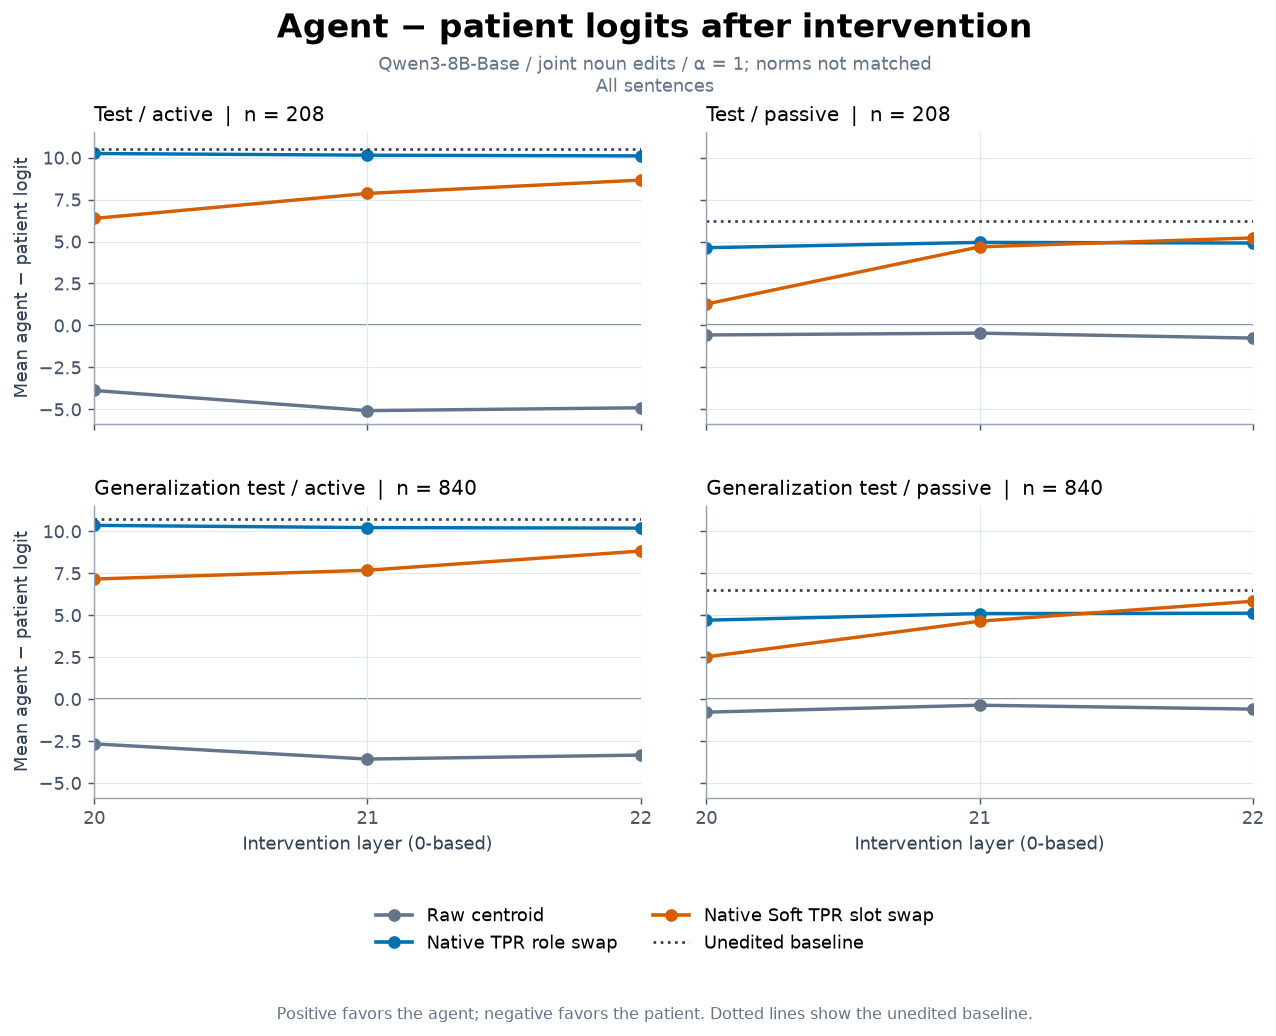

In [19]:
plot_layers(
    "mean_agent_minus_patient", "Agent − patient logits after intervention",
    "Mean agent − patient logit",
    "Positive favors the agent; negative favors the patient. Dotted lines show the unedited baseline.",
    reference=True,
)


## How often does the preference flip?

Count strict changes in either direction and divide by **all selected sentences**. A tie before or after editing is not a flip. These rates come from the saved margins.

Layers 20–22 are the recorded conditions. The run separately checked a final-block no-effect control on its first batch; that check is outside this sweep.


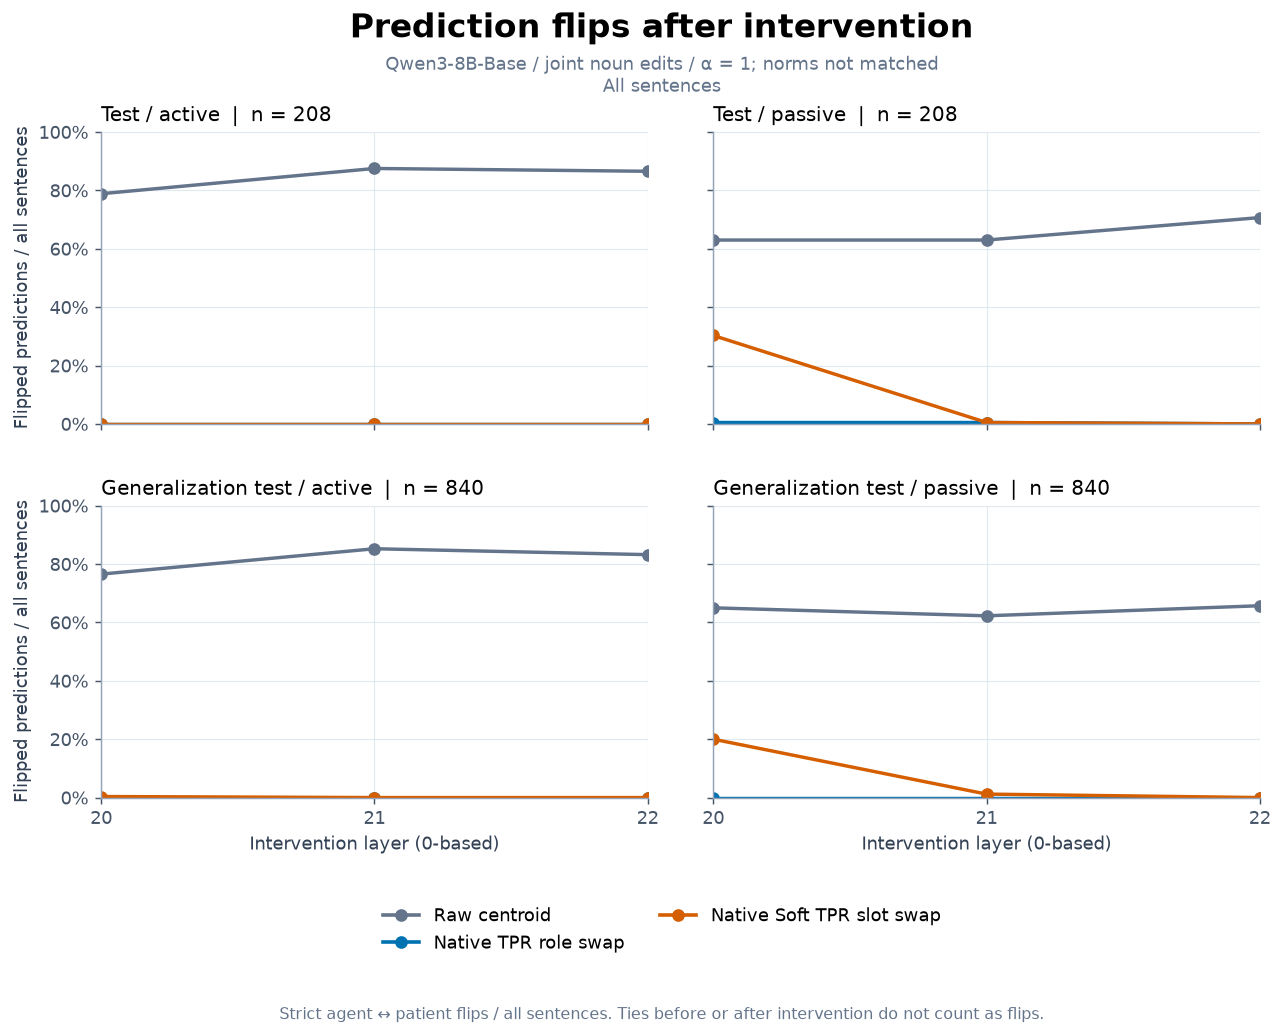

In [20]:
plot_layers(
    "flip_rate", "Prediction flips after intervention",
    "Flipped predictions / all sentences",
    "Strict agent ↔ patient flips / all sentences. Ties before or after intervention do not count as flips.",
    percent=True,
)


## Flips among baseline agent wins

For comparison with the original experiment summary, also count **agent → patient flips / baseline agent wins**. This denominator differs from the rate above. The conditional rate is undefined when a group has no baseline agent wins.


In [21]:
display(summary[KEYS + ["sentences", "baseline_agent_wins", "flips", "conditional_flip"]].round(4))


,split,voice,layer,method,sentences,baseline_agent_wins,flips,conditional_flip
0,gen_test,active,20,raw_centroid,840,840,643,0.7655
1,gen_test,active,20,soft_native_slot_swap,840,840,3,0.0036
2,gen_test,active,20,tpr_native_role_swap,840,840,0,0.0000
3,gen_test,active,21,raw_centroid,840,840,716,0.8524
4,gen_test,active,21,soft_native_slot_swap,840,840,0,0.0000
5,gen_test,active,21,tpr_native_role_swap,840,840,0,0.0000
6,gen_test,active,22,raw_centroid,840,840,699,0.8321
7,gen_test,active,22,soft_native_slot_swap,840,840,0,0.0000
8,gen_test,active,22,tpr_native_role_swap,840,840,0,0.0000
9,gen_test,passive,20,raw_centroid,840,839,546,0.6508


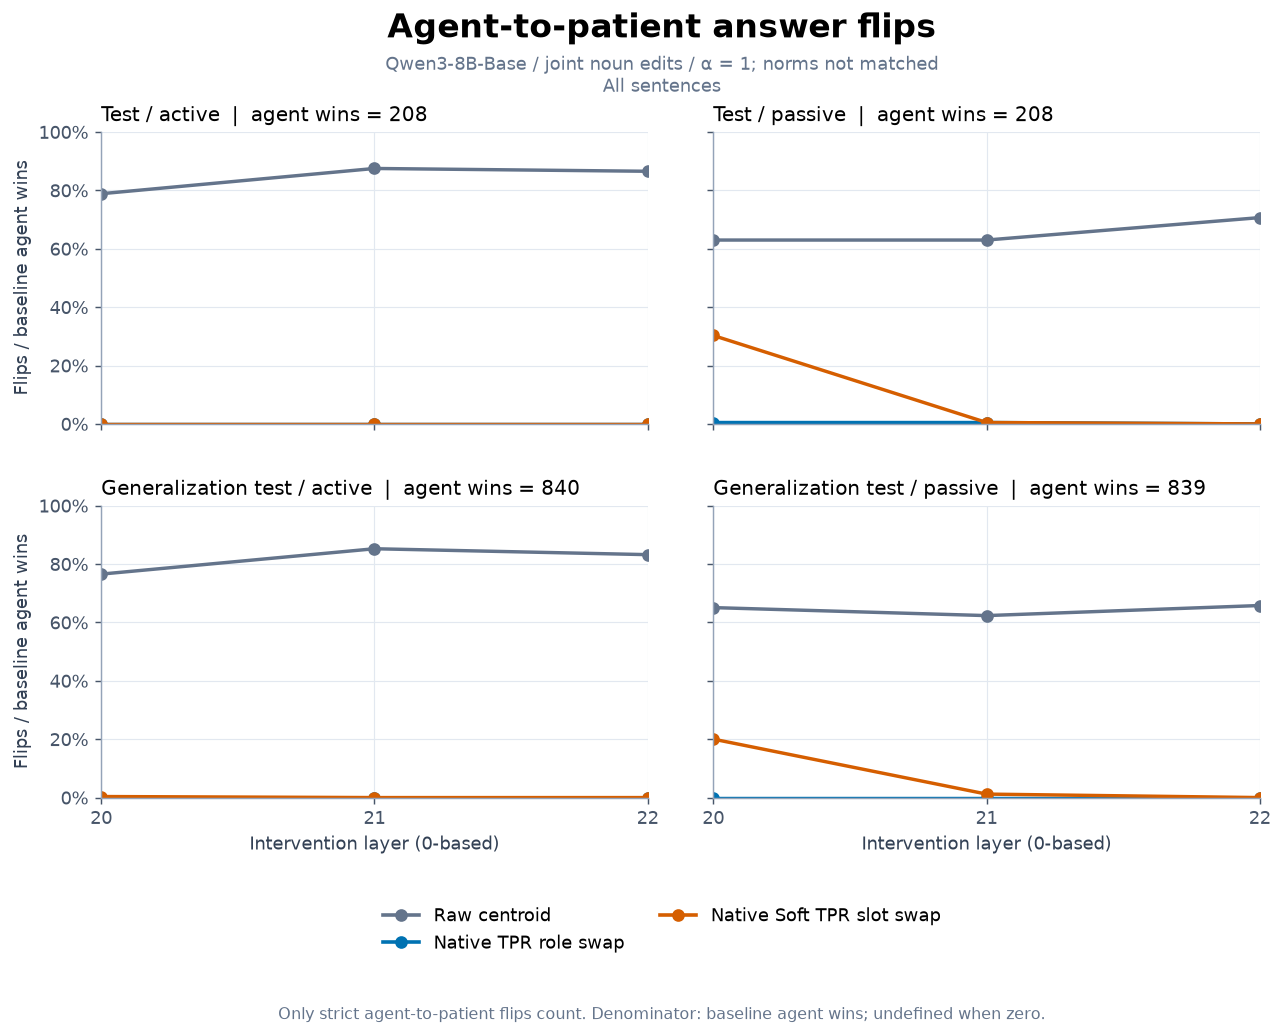

In [22]:
plot_layers(
    "conditional_flip", "Agent-to-patient answer flips",
    "Flips / baseline agent wins",
    "Only strict agent-to-patient flips count. Denominator: baseline agent wins; undefined when zero.",
    percent=True, conditional=True,
)


## How large are the edits?

α = 1 leaves each native transformation at its own norm. The table averages across the two edited noun tokens and counts exact zero edits. The experiment scripts leave zero edits at zero rather than normalizing them into nonzero vectors.


In [23]:
norm_table = summary[["split", "voice", "layer", "method", "mean_agent_edit_norm", "mean_patient_edit_norm", "zero_token_edits", "zero_sentence_edits"]].copy()
norm_table["Mean norm per token"] = (norm_table.pop("mean_agent_edit_norm") + norm_table.pop("mean_patient_edit_norm")) / 2
norm_table["method"] = norm_table["method"].map(METHOD_LABELS)
display(norm_table.rename(columns={"split": "Split", "voice": "Voice", "layer": "Layer", "method": "Method",
    "zero_token_edits": "Zero token edits", "zero_sentence_edits": "Both token edits zero"}).round(3))


,Split,Voice,Layer,Method,Zero token edits,Both token edits zero,Mean norm per token
0,gen_test,active,20,Raw centroid,0,0,59.035
1,gen_test,active,20,Native Soft TPR slot swap,5,0,42.668
2,gen_test,active,20,Native TPR role swap,0,0,27.964
3,gen_test,active,21,Raw centroid,0,0,66.122
4,gen_test,active,21,Native Soft TPR slot swap,18,0,43.843
5,gen_test,active,21,Native TPR role swap,0,0,31.718
6,gen_test,active,22,Raw centroid,0,0,80.034
7,gen_test,active,22,Native Soft TPR slot swap,4,0,49.009
8,gen_test,active,22,Native TPR role swap,0,0,38.835
9,gen_test,passive,20,Raw centroid,0,0,61.061


## Slot calibration

From here on, the tables use their full saved cohorts regardless of `FILTERS`. Raw centroids use training means; TPR exchanges role-conditioned filler profiles; Soft TPR applies one training-selected slot permutation shared across voices. Its slots have no assigned agent/patient labels.

The table counts unchanged slots and the target matches they already give without editing.


In [24]:
audit_inputs = {}
calibration_corpus = read_csv(ROOT / "data/active_pass_long/corpus.csv")
calibration, calibrated_layers = audit_calibration(RUN, plan, calibration_corpus, audit_inputs)
calibration_rows = []
for item in calibrated_layers:
    d = item["diagnostics"]
    calibration_rows.append({
        "Layer": item["layer"],
        "Slot permutation": str(item["permutation"]),
        "Training tokens": item["training_tokens"],
        "Candidates": d["candidate_count"],
        "Unchanged slots": sum(i == j for i, j in enumerate(item["permutation"])),
        "Minimum no-edit slot match (%)": 100 * sum(i == j for i, j in enumerate(item["permutation"])) / len(item["permutation"]),
        "Training MSE reduction (%)": 100 * d["relative_improvement"],
    })
display(pd.DataFrame(calibration_rows).round(4))


,Layer,Slot permutation,Training tokens,Candidates,Unchanged slots,Minimum no-edit slot match (%),Training MSE reduction (%)
0,20,"[5, 1, 2, 3, 4, 0, 6, 7]",6600,764,6,75.0,4.5038
1,21,"[3, 1, 2, 0, 4, 5, 6, 7]",6600,764,6,75.0,2.0668
2,22,"[0, 1, 2, 5, 4, 3, 6, 7]",6600,764,6,75.0,5.7077


## Can the probe still read the filler?

These diagnostics simulate **BF16(h.float() + Δh)** on cached activations. They are not live Qwen hook captures. All methods use the same TPR filler readout: source role before editing, target role afterward.

Accuracy is defined only for the 19 training-vocabulary fillers. Stable predictions for an out-of-vocabulary filler do not establish its identity. Pool counts before computing rates so groups with different denominators get the correct weight.


In [25]:
diagnostic_metadata = json.loads((RUN / "diagnostics/metadata.json").read_text())
assert diagnostic_metadata["status"] == "complete"
assert diagnostic_metadata["scientific_source_sha256"] == plan["source_sha256"]
for name, expected in diagnostic_metadata["files_sha256"].items():
    path = RUN / "diagnostics" / name
    assert digest(path) == expected
    input_hashes[str(path)] = expected
for name, expected in diagnostic_metadata["input_sha256"].items():
    assert digest(RUN / name) == expected


In [26]:
filler = pd.read_csv(RUN / "diagnostics/filler_metrics.csv")
fidelity = pd.read_csv(RUN / "diagnostics/soft_fidelity.csv")
alignment = pd.read_csv(RUN / "diagnostics/soft_alignment.csv")
for name, frame in (("filler_metrics.csv", filler), ("soft_fidelity.csv", fidelity), ("soft_alignment.csv", alignment)):
    assert len(frame) == diagnostic_metadata["metrics_rows"][name]


In [27]:
known = (filler[filler["vocabulary"] == "all"]
    .groupby(["split", "voice", "layer", "method"], as_index=False)
    [["tokens", "known_tokens", "filler_before_correct", "filler_after_target_correct"]].sum())
known["Before accuracy (%)"] = 100 * known["filler_before_correct"] / known["known_tokens"]
known["Target-role accuracy (%)"] = 100 * known["filler_after_target_correct"] / known["known_tokens"]
known["method"] = known["method"].map(METHOD_LABELS)
display(known.drop(columns=["filler_before_correct", "filler_after_target_correct"])
    .rename(columns={"split": "Split", "voice": "Voice", "layer": "Layer", "method": "Method",
                     "tokens": "All tokens", "known_tokens": "Known-filler tokens"}).round(3))


,Split,Voice,Layer,Method,All tokens,Known-filler tokens,Before accuracy (%),Target-role accuracy (%)
0,gen_test,active,20,Raw centroid,1680,792,100.0,100.000
1,gen_test,active,20,Native Soft TPR slot swap,1680,792,100.0,96.970
2,gen_test,active,20,Native TPR role swap,1680,792,100.0,100.000
3,gen_test,active,21,Raw centroid,1680,792,100.0,100.000
4,gen_test,active,21,Native Soft TPR slot swap,1680,792,100.0,98.485
5,gen_test,active,21,Native TPR role swap,1680,792,100.0,100.000
6,gen_test,active,22,Raw centroid,1680,792,100.0,100.000
7,gen_test,active,22,Native Soft TPR slot swap,1680,792,100.0,100.000
8,gen_test,active,22,Native TPR role swap,1680,792,100.0,100.000
9,gen_test,passive,20,Raw centroid,1680,792,100.0,100.000


### TPR profile error

Check how closely the local role swap reaches the ideal filler-logit profiles.


In [28]:
profile = filler[(filler["vocabulary"] == "all") & (filler["method"] == "tpr_native_role_swap")]
display(profile.groupby(["split", "voice"])["native_ideal_logits_relative_error"].agg(["min", "max"])
        .rename(columns={"min": "Minimum relative TPR profile error", "max": "Maximum relative TPR profile error"}))


Minimum relative TPR profile error  \
split    voice                                         
gen_test active                             0.000458   
         passive                            0.000522   
test     active                             0.000373   
         passive                            0.000375   

                  Maximum relative TPR profile error  
split    voice                                        
gen_test active                             0.000644  
         passive                            0.000646  
test     active                             0.000531  
         passive                            0.000555

## Do the reordered codes survive re-encoding?

A permutation preserves the target's code multiset exactly. Adding the decoded difference and re-encoding the hidden state can still produce different codes.

Fixed slots already match the target without editing, as counted in the calibration table. Read per-slot agreement alongside exact recovery of all slots and of the code multiset. These are code diagnostics, not tests of word identity.


In [29]:
counts = (fidelity[fidelity["vocabulary"] == "all"]
    .groupby(["split", "voice", "layer"], as_index=False)
    [["tokens", "slot_matches", "total_slots", "all_codes_match_tokens", "bag_retained_tokens", "target_bag_preserved_tokens"]].sum())
counts["Target slots recovered (%)"] = 100 * counts["slot_matches"] / counts["total_slots"]
counts["All slots recovered (%)"] = 100 * counts["all_codes_match_tokens"] / counts["tokens"]
counts["Re-encoded code multiset preserved (%)"] = 100 * counts["bag_retained_tokens"] / counts["tokens"]
counts["Target code multiset preserved (%)"] = 100 * counts["target_bag_preserved_tokens"] / counts["tokens"]
display(counts[["split", "voice", "layer", "tokens", "total_slots", "Target slots recovered (%)", "All slots recovered (%)",
    "Re-encoded code multiset preserved (%)", "Target code multiset preserved (%)"]]
    .rename(columns={"split": "Split", "voice": "Voice", "layer": "Layer", "tokens": "Tokens", "total_slots": "Slots"}).round(3))


,Split,Voice,Layer,Tokens,Slots,Target slots recovered (%),All slots recovered (%),Re-encoded code multiset preserved (%),Target code multiset preserved (%)
0,gen_test,active,20,1680,13440,69.754,10.952,11.012,100.0
1,gen_test,active,21,1680,13440,64.918,5.179,5.179,100.0
2,gen_test,active,22,1680,13440,67.470,7.500,8.571,100.0
3,gen_test,passive,20,1680,13440,64.710,3.631,3.631,100.0
4,gen_test,passive,21,1680,13440,59.435,4.702,4.940,100.0
5,gen_test,passive,22,1680,13440,72.068,10.655,10.952,100.0
6,test,active,20,416,3328,84.525,25.962,25.962,100.0
7,test,active,21,416,3328,81.400,15.385,15.385,100.0
8,test,active,22,416,3328,84.375,21.154,25.240,100.0
9,test,passive,20,416,3328,79.537,8.894,9.135,100.0


## Does the permutation move codes toward the twin?

Compare the original quantized codes with those of the same filler in its opposite-role twin sentence. Only training pairs selected the permutation. Validation and held-out twins enter this saved diagnostic after the run, never the construction or selection of held-out edits.

A positive reduction means the frozen permutation moved codes closer to their twins on average. It does not establish that individual slots represent agent and patient.


In [30]:
alignment_view = alignment.copy()
alignment_view["MSE reduction (%)"] = 100 * alignment_view.pop("relative_mse_reduction")
display(alignment_view.rename(columns={"split": "Split", "voice": "Voice", "layer": "Layer", "tokens": "Tokens",
                                      "identity_mse": "Identity MSE", "permuted_mse": "Permuted MSE"}).round(5))


,Layer,Split,Voice,Tokens,Identity MSE,Permuted MSE,MSE reduction (%)
0,20,val,active,412,0.32954,0.32431,1.58674
1,20,val,passive,412,0.35540,0.32923,7.36256
2,20,test,active,416,0.33736,0.32767,2.87080
3,20,test,passive,416,0.35471,0.32973,7.04110
4,20,gen_test,active,1680,0.32932,0.32967,-0.10686
5,20,gen_test,passive,1680,0.33831,0.32434,4.12952
6,21,val,active,412,0.36513,0.35506,2.75634
7,21,val,passive,412,0.32219,0.31935,0.88016
8,21,test,active,416,0.36818,0.35558,3.42288
9,21,test,passive,416,0.32458,0.32016,1.36278


## Save the tables

Save selected sentence counts, layer statistics, and source hashes. Calibration and local diagnostic exports keep their full saved cohorts. Figures stay inline. These curves describe the fixed corpus; no uncertainty intervals are estimated.


In [31]:
input_hashes.update({str(path): digest(path) for path in audit_inputs.values()})
for name, expected in input_hashes.items():
    assert digest(Path(name)) == expected, name
baseline_stats.to_csv(FIGURES / "baseline_statistics.csv")
summary.to_csv(FIGURES / "layer_statistics.csv", index=False)
pd.DataFrame(calibration_rows).to_csv(FIGURES / "full_cohort_calibration.csv", index=False)
known.to_csv(FIGURES / "full_cohort_filler_statistics.csv", index=False)
counts.to_csv(FIGURES / "full_cohort_slot_statistics.csv", index=False)
alignment_view.to_csv(FIGURES / "full_cohort_alignment.csv", index=False)


In [32]:
provenance = {
    "filters": active_filters,
    "selected_sentences": len(baseline),
    "run_directory": str(RUN),
    "run_created_at": plan["created_at"],
    "model": plan["model"], "revision": plan["revision"],
    "layers": LAYERS, "methods": list(METHODS),
    "alpha": plan["fixed_alpha"], "norm_matching": plan["norm_matching"],
    "edited_positions": "Both noun tokens jointly at one layer per condition",
    "source_sha256": input_hashes,
    "baseline_preference": "count(agent_logit > patient_logit) / all selected sentences",
    "answer_score": "mean(agent minus patient logit), computed as -edited_margin",
    "prediction_flip_rate": "strict agent-to-patient or patient-to-agent flips / all selected sentences",
    "conditional_flip_rate": "strict agent-to-patient flips / baseline agent wins; undefined when zero",
    "ties": "Neither preference nor flip; included in the all-sentence denominator",
    "diagnostic_scope": "Full saved cohorts, independent of FILTERS",
    "uncertainty": "Descriptive curves; no uncertainty intervals",
}
(FIGURES / "plot_metadata.json").write_text(json.dumps(provenance, indent=2) + "\n")
print(f"Verified {len(input_hashes)} source hashes.")
print(f"Tables and provenance saved to {FIGURES}")


Verified 81 source hashes.
Tables and provenance saved to /home/ldomenichelli/Workspace/AC-TPR-native-nov6/notebook/figures/native_tpr_steering_results/all


## Reading the results

Compare answer scores and flips with the baseline preference and edit norms. This run uses joint noun edits, voice-specific demonstrations, and three layers chosen from historical raw-steering peaks; the results remain exploratory.

Probe or code recovery describes the local representation, without guaranteeing a changed answer or preserved word identity in Qwen. `gen_test` uses new fillers in the same syntactic templates, where semantic role and token position are not fully disentangled.


## Rerun the experiment

The walkthroughs rerun CPU calculations; this report reads the completed GPU evaluation. To repeat the full run, call the launcher from the repository root with a **new output directory**:

```bash
TPR_PYTHON=/tmp/tpr-binding-gpu-venv/bin/python \
  bash scripts/temporary/execute_native_tpr_nov6.sh ac-tpr-cache/NEW_NATIVE_RUN
```

This runs preparation, calibration, model evaluation, diagnostics, and reporting. It is a manual command, so running the notebook cells does not launch another GPU job.

Implementation: [driver](../scripts/temporary/run_native_tpr_nov6.py), [TPR edit](../scripts/temporary/native_tpr_interventions.py), [Soft TPR edit](../scripts/temporary/native_soft_interventions.py), [diagnostics](../scripts/temporary/diagnose_native_tpr_nov6.py).
